In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# load the csv
df = pd.read_csv("battery_data.csv")

arr = df.to_numpy()
hours_arr = arr[:,0].astype(float)
life_arr = arr[:,1].astype(float)

[  0.  15.  30.  45.  60.  75.  90. 105. 120. 135. 150. 165. 180. 195.
 210. 225. 240. 255. 270. 285. 300.]
[100.  96.  92.  88.  85.  81.  77.  73.  69.  65.  62.  58.  55.  50.
  47.  43.  39.  35.  31.  26.  22.]


<function matplotlib.pyplot.show(close=None, block=None)>

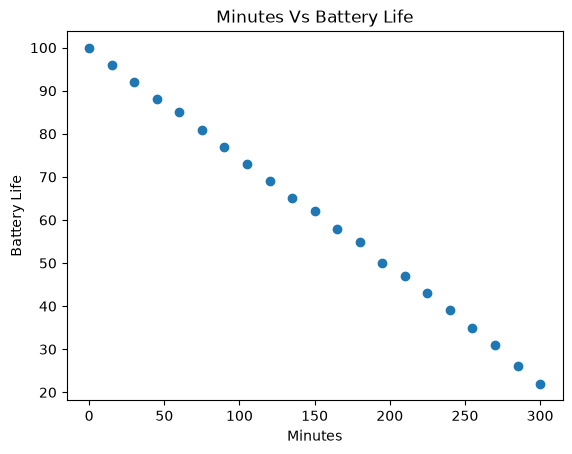

In [ ]:
plt.scatter(hours_arr, life_arr)
plt.title("Hours Vs Battery Life")
plt.xlabel("Hours")
plt.ylabel("Battery Life")
plt.show

In [46]:
# cost calculation

def cost(x_i: np.ndarray, y_i: np.ndarray, w: float, b: float) -> float:    
    f_wb = w * x_i + b
    sum = (f_wb - y_i) ** 2
    sum = np.sum(sum)
    cost = sum / (2 * len(x_i))
    return cost

In [47]:
def gradient(x_i: np.ndarray, y_i: np.ndarray, w: float, b: float) -> tuple:
    f_wb = w * x_i + b
    sum_b = f_wb - y_i
    sum_w = sum_b * x_i
    sum_w = np.sum(sum_w)
    sum_b = np.sum(sum_b)

    grad_w = sum_w / (len(x_i))
    grad_b = sum_b / (len(x_i))
    return grad_w, grad_b

In [ ]:
# change w and b simultaneously until we done

def lin_regression(x_i: np.ndarray, y_i: np.ndarray, alpha: float, cost, gradient) -> tuple:
    costs = []
    parameters = []
    w = 0
    b = 0
    prev_cost = 0
    curr_cost = cost(x_i, y_i, w, b)
    iters = 0
    while (abs(prev_cost - curr_cost) > 0.0000001):
        prev_cost = curr_cost
        grad_w, grad_b = gradient(x_i, y_i, w, b)
        w = w - alpha * grad_w
        b = b - alpha * grad_b
        curr_cost = cost(x_i, y_i, w, b)
        costs.append(curr_cost)
        parameters.append([w, b])
        if iters % 50 == 0:
            print(f"iter: {iters} w: {w} b: {b} cost: {curr_cost}")
        iters += 1            
    return w, b, costs, parameters

In [ ]:
w_final, b_final, costs, parameters = lin_regression(hours_arr, life_arr, 0.1, cost, gradient)
print(w_final, b_final)

iter: 0 w: 0.4634035714285714 b: 0.004005238095238095 cost: 2167.3001133544626
iter: 30000 w: 0.03303561369329112 b: 40.75678792409478 cost: 471.7197882995775
iter: 60000 w: -0.08478261739814918 b: 64.90931457105896 cost: 165.7719302831441
iter: 90000 w: -0.15460678411215115 b: 79.22314386164742 cost: 58.31512023791769
iter: 120000 w: -0.1959875976937172 b: 87.70613663316662 cost: 20.573506029667524
iter: 150000 w: -0.2205116530925638 b: 92.73352412680954 cost: 7.317673826526514
iter: 180000 w: -0.23504566635018348 b: 95.71297084944405 cost: 2.6618823061042556
iter: 210000 w: -0.24365914963984694 b: 97.47871951796147 cost: 1.0266477656045878
iter: 240000 w: -0.24876387144422318 b: 98.52517835767924 cost: 0.45231105170491276
iter: 270000 w: -0.2517891498157927 b: 99.14535501291277 cost: 0.2505891257281605
iter: 300000 w: -0.2535820602967592 b: 99.51289845475533 cost: 0.17973916187429131
iter: 330000 w: -0.2546446163983616 b: 99.73072055512212 cost: 0.1548548199576292
iter: 360000 w: -0.

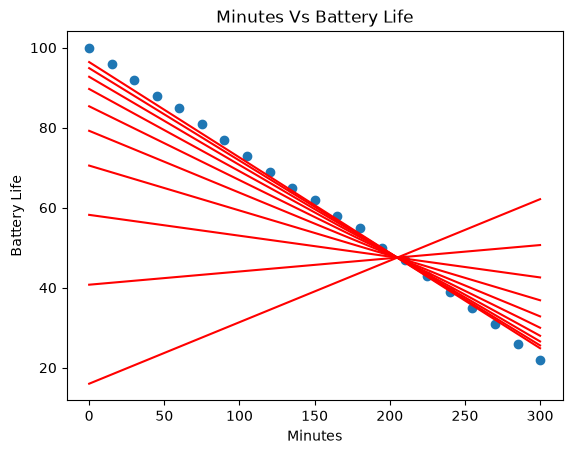

In [ ]:
plt.scatter(hours_arr, life_arr)
for i in range(50, 400, 5):
    plt.plot(hours_arr, parameters[i][0]*hours_arr + parameters[i][1], color="red", label="model")
plt.title("Minutes Vs Battery Life")
plt.xlabel("Minutes")
plt.ylabel("Battery Life")
plt.show()